# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours   
**Student:** Mohamed Es-saih
---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation

The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### Tasks
1. Report dataset dimensions, class balance, missing values, duplicates and summary statistics.
2. Identify the identifier and the post-scan field. Explain why each should be excluded.
3. Investigate `Virtual_to_Raw_Size_Ratio`: identify the suspicious parser value `99999.0`. Decide how to handle it and justify your choice.
4. Visualize at least two feature relationships with the target. Discuss whether a single linear boundary is likely to capture all patterns.
5. Define the prediction task, positive class, and the operational meaning of FP and FN.

**Do not** use `VT_PostScan_Detections` as an input feature. It is recorded after the event and would cause target leakage.

In [3]:
print("Shape:",df_pe.shape)
print("Target counts:",df_pe.Is_Malware.value_counts().sort_index().to_dict())
print("Malware prevalence:",round(df_pe.Is_Malware.mean(),4))
print("Missing values:",df_pe.isna().sum().to_dict())
print("Duplicate rows:",int(df_pe.duplicated().sum()))
display(df_pe.describe().T)

Shape: (6000, 15)
Target counts: {0: 4389, 1: 1611}
Malware prevalence: 0.2685
Missing values: {'SHA256_File_ID': 0, 'Max_Section_Entropy': 0, 'Import_Count': 229, 'Suspicious_API_Imports': 0, 'Has_Valid_Signature': 0, 'Has_RWX_Section': 0, 'Virtual_to_Raw_Size_Ratio': 0, 'Resource_Entropy': 289, 'Num_Embedded_URLs_IPs': 0, 'Abnormal_Compile_Timestamp': 0, 'Num_Sections': 0, 'Has_TLS_Callback': 0, 'Export_Count': 0, 'VT_PostScan_Detections': 0, 'Is_Malware': 0}
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Max_Section_Entropy,6000.0,5.709010,1.170152,2.146111,4.821742,5.639862,6.604762,7.990000
Import_Count,5771.0,83.386866,50.301130,0.000000,41.184528,85.663796,120.408591,320.325585
Suspicious_API_Imports,6000.0,2.800167,3.094430,0.000000,1.000000,2.000000,3.000000,24.000000
Has_Valid_Signature,6000.0,0.630833,0.482619,0.000000,0.000000,1.000000,1.000000,1.000000
Has_RWX_Section,6000.0,0.149833,0.356938,0.000000,0.000000,0.000000,0.000000,1.000000
Virtual_to_Raw_Size_Ratio,6000.0,984.890348,9868.008483,0.367195,0.955570,1.129836,1.366755,99999.000000
Resource_Entropy,5711.0,4.535160,1.501097,0.000000,3.483114,4.432941,5.517712,7.990000
Num_Embedded_URLs_IPs,6000.0,1.468333,1.951742,0.000000,0.000000,1.000000,2.000000,11.000000
Abnormal_Compile_Timestamp,6000.0,0.114833,0.318847,0.000000,0.000000,0.000000,0.000000,1.000000
Num_Sections,6000.0,4.758667,1.784551,1.000000,3.000000,5.000000,6.000000,10.000000


Parser sentinel count: 59


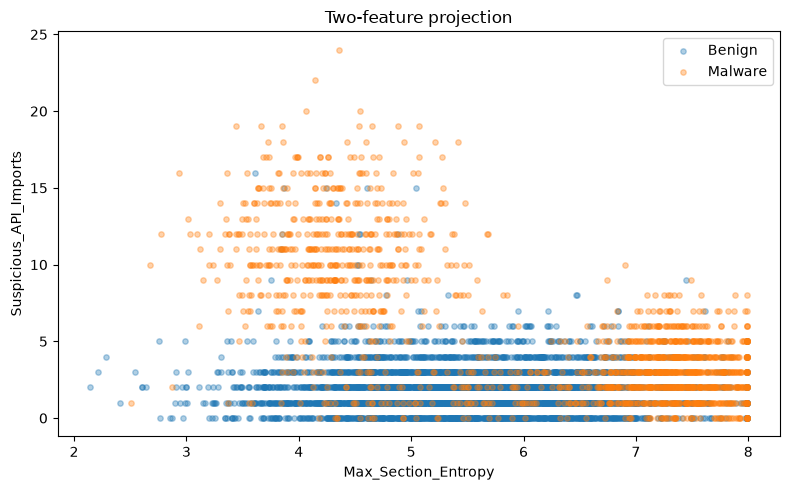

In [4]:
sentinel_count=int((df_pe.Virtual_to_Raw_Size_Ratio==99999.0).sum())
print("Parser sentinel count:",sentinel_count)
fig,ax=plt.subplots(figsize=(8,5))
for label,name in [(0,"Benign"),(1,"Malware")]:
 d=df_pe[df_pe.Is_Malware==label]
 ax.scatter(d.Max_Section_Entropy,d.Suspicious_API_Imports,alpha=.35,s=15,label=name)
ax.set(xlabel="Max_Section_Entropy",ylabel="Suspicious_API_Imports",title="Two-feature projection")
ax.legend(); plt.tight_layout(); plt.show()

In [5]:
y=df_pe.Is_Malware.astype(int)
X=df_pe.drop(columns=["SHA256_File_ID","VT_PostScan_Detections","Is_Malware"]).copy()
X["Virtual_to_Raw_Size_Ratio"]=X.Virtual_to_Raw_Size_Ratio.replace(99999.0,np.nan)
FEATURES=X.columns.tolist()
print("Predictive feature count:",len(FEATURES),FEATURES)

Predictive feature count: 12 ['Max_Section_Entropy', 'Import_Count', 'Suspicious_API_Imports', 'Has_Valid_Signature', 'Has_RWX_Section', 'Virtual_to_Raw_Size_Ratio', 'Resource_Entropy', 'Num_Embedded_URLs_IPs', 'Abnormal_Compile_Timestamp', 'Num_Sections', 'Has_TLS_Callback', 'Export_Count']


## Phase 2 — Design a leakage-safe evaluation protocol

Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### Tasks
1. Create `X_dev`, `X_test`, `y_dev`, `y_test`.
2. Define a preprocessing pipeline with median imputation. Use `RobustScaler` for Logistic Regression; explain why scaling is generally unnecessary for tree models.
3. Build candidate pipelines:
   - Logistic Regression (linear baseline)
   - Deep Decision Tree (single white-box tree)
   - Random Forest (bagging)
   - LightGBM if installed; otherwise `HistGradientBoostingClassifier` and label it accurately (not LightGBM).
4. Use the same CV folds and report train F1, validation F1, PR-AUC and fit time.
5. Interpret bias/variance and choose candidates worth further investigation.

In [6]:
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.20,random_state=SEED,stratify=y)
def pipe(est,scale=False):
 steps=[("imputer",SimpleImputer(strategy="median"))]
 if scale: steps.append(("scaler",RobustScaler()))
 steps.append(("model",est))
 return Pipeline(steps)
models={"Logistic Regression":pipe(LogisticRegression(max_iter=1500),True),
"Decision Tree":pipe(DecisionTreeClassifier(random_state=SEED)),
"Random Forest":pipe(RandomForestClassifier(n_estimators=70,min_samples_leaf=2,random_state=SEED,n_jobs=1))}
try:
 from lightgbm import LGBMClassifier
 boost_name="LightGBM"
 boost=LGBMClassifier(n_estimators=70,learning_rate=.05,num_leaves=20,random_state=SEED,verbosity=-1,n_jobs=1)
except Exception:
 from sklearn.ensemble import HistGradientBoostingClassifier
 boost_name="HistGradientBoosting (fallback)"
 boost=HistGradientBoostingClassifier(max_iter=120,random_state=SEED)
models[boost_name]=pipe(boost)
stack=StackingClassifier(estimators=[("lr",LogisticRegression(max_iter=1000)),("rf",RandomForestClassifier(n_estimators=50,random_state=SEED,n_jobs=1))],final_estimator=LogisticRegression(),cv=3,n_jobs=1)
models["Stacking"]=pipe(stack)
print("Development:",X_dev.shape,"Lockbox:",X_test.shape,"Boosting:",boost_name)

Development: (4800, 12) Lockbox: (1200, 12) Boosting: HistGradientBoosting (fallback)


In [7]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
rows=[]; cv_results={}
for name,est in models.items():
 print("CV:",name)
 r=cross_validate(est,X_dev,y_dev,cv=cv,scoring={"f1":"f1","pr_auc":"average_precision"},return_train_score=True,n_jobs=1)
 cv_results[name]=r
 a=r["train_f1"].mean(); b=r["test_f1"].mean()
 rows.append({"Model":name,"Train F1":a,"Validation F1":b,"Validation PR-AUC":r["test_pr_auc"].mean(),"Fit time (s)":r["fit_time"].mean(),"Train–validation F1 gap":a-b})
cv_table=pd.DataFrame(rows).sort_values("Validation PR-AUC",ascending=False).reset_index(drop=True)
display(cv_table.round(4))
best_name=cv_table.iloc[0]["Model"]
rfscore=float(cv_table.loc[cv_table.Model=="Random Forest","Validation PR-AUC"].iloc[0])
tree_name="Random Forest"  # fixed supported tree ensemble for TreeSHAP and operational analysis
print("Top PR-AUC:",best_name,"| Tree model for explanations:",tree_name)
print("Largest gap:",cv_table.loc[cv_table["Train–validation F1 gap"].idxmax(),"Model"])

CV: Logistic Regression
CV: Decision Tree
CV: Random Forest
CV: HistGradientBoosting (fallback)
CV: Stacking


,Model,Train F1,Validation F1,Validation PR-AUC,Fit time (s),Train–validation F1 gap
0,Logistic Regression,0.9231,0.9238,0.9080,0.0351,-0.0007
1,Random Forest,0.9296,0.9237,0.9067,0.5849,0.0059
2,HistGradientBoosting (fallback),0.9906,0.9216,0.9063,1.8084,0.0690
3,Stacking,0.9273,0.9252,0.9040,3.1878,0.0021
4,Decision Tree,1.0000,0.8301,0.7330,0.0507,0.1699


Top PR-AUC: Logistic Regression | Tree model for explanations: Random Forest
Largest gap: Decision Tree


### Decision checkpoint 1 — Select a shortlist

Answer with evidence from your table:
1. Which model shows the largest train–validation gap? What does it suggest?
2. Does the linear baseline already perform competitively?
3. Does Random Forest improve on the single tree?
4. Does boosting improve PR-AUC enough to justify its complexity?
5. Is stacking justified by the measured gain, runtime and deployment context? Do not assume that a more complex model must win.

**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements.

In [8]:
lat=[]
fitted={}
for name in dict.fromkeys(["Logistic Regression","Random Forest",best_name]):
 m=clone(models[name]).fit(X_dev,y_dev); fitted[name]=m
 m.predict_proba(X_test.iloc[:100])
 t=time.perf_counter()
 for _ in range(20): m.predict_proba(X_test)
 ms=(time.perf_counter()-t)/20*1000/len(X_test)*1000
 lat.append({"Model":name,"Batch size":len(X_test),"Milliseconds / 1,000 files":ms})
display(pd.DataFrame(lat).round(3))
print("Timing includes predict_proba on loaded feature rows; excludes parsing, I/O, networking, queueing and analyst work.")

,Model,Batch size,"Milliseconds / 1,000 files"
0,Logistic Regression,1200,3.883
1,Random Forest,1200,21.673


Timing includes predict_proba on loaded feature rows; excludes parsing, I/O, networking, queueing and analyst work.


## Phase 3 — Error forensics: investigate a real disagreement

Choose a held-out test observation for which the candidate models disagree. Do not hard-code a story before verifying the predictions.

### Tasks
1. Generate probabilities for the same test observations from Logistic Regression and your selected tree ensemble.
2. Find a malware observation where Logistic Regression predicts benign at the chosen illustrative threshold while the tree model predicts malware. If no such observation exists, report that honestly and choose another meaningful disagreement.
3. Print the ground-truth label, feature values, probabilities and predictions.
4. Build global and local SHAP explanations for a supported tree model.
5. Interpret a beeswarm and a local waterfall. Explain why SHAP is not causal evidence.

In [9]:
for name in ["Logistic Regression",tree_name]:
 if name not in fitted: fitted[name]=clone(models[name]).fit(X_dev,y_dev)
lr_model=fitted["Logistic Regression"]; tree_model=fitted[tree_name]
p_lr=lr_model.predict_proba(X_test)[:,1]; p_tree=tree_model.predict_proba(X_test)[:,1]
pred_lr=(p_lr>=.5).astype(int); pred_tree=(p_tree>=.5).astype(int)
idx=np.flatnonzero(pred_lr!=pred_tree)
if len(idx)==0: raise RuntimeError("No disagreement at threshold 0.50 in this run.")
mal=[i for i in idx if int(y_test.iloc[i])==1]
case_pos=int(mal[0] if mal else idx[0]); case_X=X_test.iloc[[case_pos]]; case=X_test.iloc[case_pos]
print("Original row index:",X_test.index[case_pos],"| True label:",int(y_test.iloc[case_pos]))
print("LR probability/prediction:",p_lr[case_pos],pred_lr[case_pos],"threshold=0.50")
print(tree_name,"probability/prediction:",p_tree[case_pos],pred_tree[case_pos],"threshold=0.50")
display(case.to_frame("Observed feature value"))

Original row index: 5787 | True label: 1
LR probability/prediction: 0.30443926149283496 0 threshold=0.50
Random Forest probability/prediction: 0.6113945578231292 1 threshold=0.50


,Observed feature value
Max_Section_Entropy,4.603163
Import_Count,116.690922
Suspicious_API_Imports,3.000000
Has_Valid_Signature,0.000000
Has_RWX_Section,0.000000
Virtual_to_Raw_Size_Ratio,0.944756
Resource_Entropy,NaN
Num_Embedded_URLs_IPs,2.000000
Abnormal_Compile_Timestamp,0.000000
Num_Sections,9.000000


,Feature,SHAP value,Observed value
9,Num_Sections,0.267976,9.000000
11,Export_Count,0.259818,1.000000
3,Has_Valid_Signature,0.008366,0.000000
0,Max_Section_Entropy,-0.001434,4.603163
10,Has_TLS_Callback,-0.001685,0.000000
8,Abnormal_Compile_Timestamp,-0.006328,0.000000
4,Has_RWX_Section,-0.009969,0.000000
1,Import_Count,-0.012593,116.690922
6,Resource_Entropy,-0.012627,4.442090
7,Num_Embedded_URLs_IPs,-0.029616,2.000000


Three largest positive contributions:


,Feature,SHAP value,Observed value
9,Num_Sections,0.267976,9.0
11,Export_Count,0.259818,1.0
3,Has_Valid_Signature,0.008366,0.0


Two largest negative contributions:


,Feature,SHAP value,Observed value
5,Virtual_to_Raw_Size_Ratio,-0.062731,0.944756
2,Suspicious_API_Imports,-0.055376,3.000000


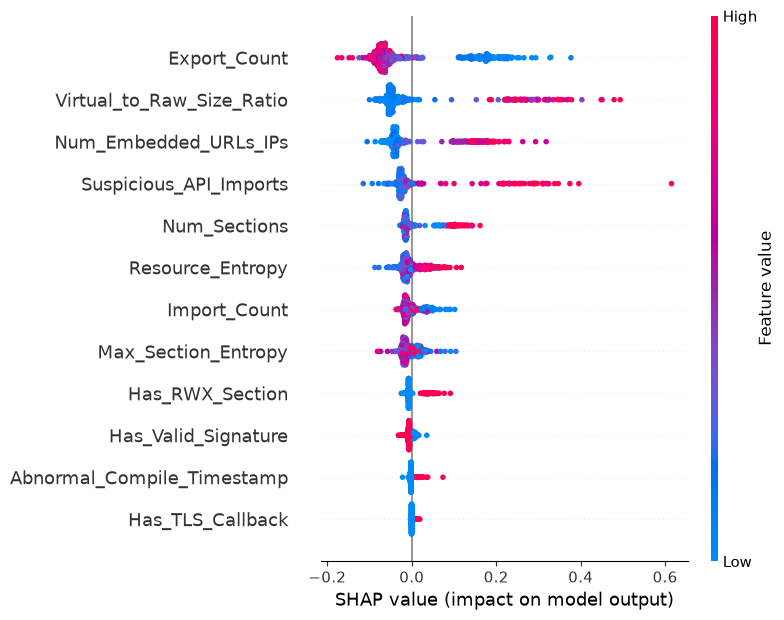

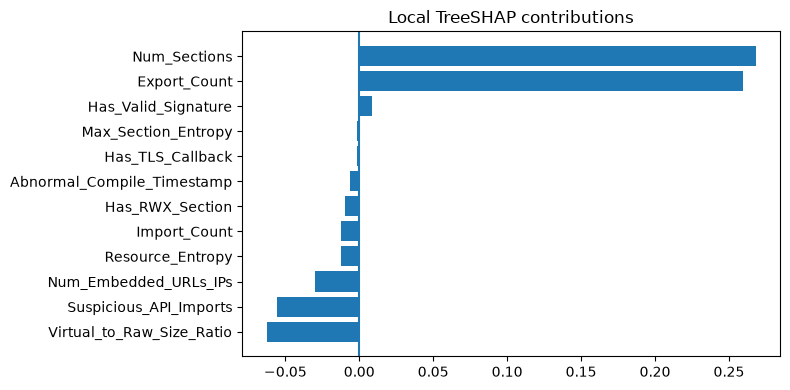

In [10]:
import shap
tree_est=tree_model.named_steps["model"]
imputer=tree_model.named_steps["imputer"]
X_dev_imp=pd.DataFrame(imputer.transform(X_dev),columns=FEATURES,index=X_dev.index)
X_case_imp=pd.DataFrame(imputer.transform(case_X),columns=FEATURES,index=case_X.index)
explainer=shap.TreeExplainer(tree_est)
sv=explainer.shap_values(X_case_imp)
if isinstance(sv,list): local=np.asarray(sv[1])[0]
else:
 sv=np.asarray(sv); local=sv[0,:,1] if sv.ndim==3 else sv[0]
shap_table=pd.DataFrame({"Feature":FEATURES,"SHAP value":local,"Observed value":X_case_imp.iloc[0].values})
display(shap_table.sort_values("SHAP value",ascending=False))
print("Three largest positive contributions:"); display(shap_table.nlargest(3,"SHAP value"))
print("Two largest negative contributions:"); display(shap_table.nsmallest(2,"SHAP value"))
# SHAP global summary uses a bounded development sample for speed
X_shap=X_dev_imp.sample(min(500,len(X_dev_imp)),random_state=SEED)
sv_global=explainer.shap_values(X_shap)
if isinstance(sv_global,list): sv_global=sv_global[1]
else:
 sv_global=np.asarray(sv_global)
 if sv_global.ndim==3: sv_global=sv_global[:,:,1]
shap.summary_plot(sv_global,X_shap,feature_names=FEATURES,show=False); plt.tight_layout(); plt.show()
plt.figure(figsize=(8,4)); q=shap_table.sort_values("SHAP value")
plt.barh(q.Feature,q["SHAP value"]); plt.axvline(0); plt.title("Local TreeSHAP contributions"); plt.tight_layout(); plt.show()

## Phase 4 — Translate model scores into a SOC decision

For the AtlasPay teaching scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.

\[
C(\tau)=25\,FP(\tau)+500\,FN(\tau)
\]

### Critical protocol
Select the threshold using development data only (for example, out-of-fold development predictions). Freeze the selected threshold. Evaluate it once on the lockbox test set. Never search test thresholds and report the minimum as final performance.

### Tasks
1. Generate out-of-fold probabilities for each shortlisted model on the development set.
2. Find the cost-minimizing threshold on those OOF predictions.
3. Freeze the threshold and evaluate FP, FN, precision, recall and cost on the test set.
4. Repeat threshold selection under `C_FP = $2,000` using development predictions. Explain why the preferred threshold changes.
5. Discuss the limitations of the cost assumptions and whether the dataset prevalence represents the intended deployment environment.

**Capacity check:** Compare the number of test-set alerts at your frozen threshold with the scenario’s 120-alert/day target only as an indicative exercise. The test set is a sample, the dataset prevalence is synthetic, and a simple test-set count must not be presented as a validated daily alert forecast. Explain what real telemetry and calibration would be required.

In [11]:
COST_FN=500; COST_FP_TRIAGE=25; COST_FP_BLOCK=2000
decision_model=models[tree_name]
oof=cross_val_predict(clone(decision_model),X_dev,y_dev,cv=cv,method="predict_proba",n_jobs=1)[:,1]
grid=np.linspace(.01,.99,99)
def metrics_cost(ytrue,prob,t,cfp):
 pred=(np.asarray(prob)>=t).astype(int); tn,fp,fn,tp=confusion_matrix(ytrue,pred,labels=[0,1]).ravel()
 return cfp*fp+COST_FN*fn
def select_t(ytrue,prob,cfp):
 vals=[(metrics_cost(ytrue,prob,t,cfp),t) for t in grid]; best=min(v[0] for v in vals)
 return max(t for c,t in vals if c==best)
t_triage=select_t(y_dev,oof,COST_FP_TRIAGE); t_block=select_t(y_dev,oof,COST_FP_BLOCK)
print("Theoretical triage threshold:",COST_FP_TRIAGE/(COST_FP_TRIAGE+COST_FN))
print("Theoretical blocking threshold:",COST_FP_BLOCK/(COST_FP_BLOCK+COST_FN))
print("OOF-selected triage threshold:",t_triage,"| blocking threshold:",t_block)
final_model=clone(decision_model).fit(X_dev,y_dev); prob_test=final_model.predict_proba(X_test)[:,1]
def eval_lockbox(t,cfp,label):
 pred=(prob_test>=t).astype(int); tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
 return {"Scenario":label,"Frozen threshold":t,"TP":tp,"TN":tn,"FP":fp,"FN":fn,
 "Precision":precision_score(y_test,pred,zero_division=0),"Recall":recall_score(y_test,pred,zero_division=0),
 "Total cost":cfp*fp+COST_FN*fn,"Cost @ 0.50":metrics_cost(y_test,prob_test,.5,cfp),"Test alerts":int(pred.sum())}
lockbox_costs=pd.DataFrame([eval_lockbox(t_triage,25,"Analyst-assisted triage"),eval_lockbox(t_block,2000,"Inline blocking")])
display(lockbox_costs.round(4))
print("Lockbox is evaluated once; test alert counts are not daily production forecasts. Test size:",len(y_test))

Theoretical triage threshold: 0.047619047619047616
Theoretical blocking threshold: 0.8
OOF-selected triage threshold: 0.45 | blocking threshold: 0.6


,Scenario,Frozen threshold,TP,TN,FP,FN,Precision,Recall,Total cost,Cost @ 0.50,Test alerts
0,Analyst-assisted triage,0.45,287,869,9,35,0.9696,0.8913,17725,17700,296
1,Inline blocking,0.60,286,870,8,36,0.9728,0.8882,34000,33500,294


Lockbox is evaluated once; test alert counts are not daily production forecasts. Test size: 1200


## Part F — Executive decision memo to AtlasPay CISO

**Recommendation:** begin with shadow mode followed by analyst-assisted triage; do not enable autonomous blocking on this evidence.

The positive class is `Is_Malware = 1`; one observation is a Windows PE file at first inspection. The dataset is deterministic synthetic teaching data, not AtlasPay telemetry or the real EMBER benchmark. Its prevalence, scores and test alert counts cannot be treated as production estimates.

Use the five-fold CV table to compare validation PR-AUC/F1, train–validation gap, fitting time and complexity. The notebook selects a tree model for the local explanation and cost analysis. A verified held-out disagreement and its observed feature values are printed above. TreeSHAP values explain the selected model output only; they are not causal proof or a malware verdict.

The OOF-selected triage and blocking thresholds are frozen before one lockbox evaluation. Cost weights are illustrative. The Bayes thresholds under calibrated probabilities and unconstrained capacity are 25/(25+500) = **0.0476** for triage and 2000/(2000+500) = **0.8000** for blocking. Empirical thresholds may differ because of imperfect calibration, finite samples and model limitations.

The planning target is at most 120 alerts/day from 12,000 PE files/day. A lockbox alert count cannot establish this capacity target: production prevalence, representative sampling, calibration and full-pipeline queue testing are missing. Latency measured here is model-only batch prediction and excludes parsing, I/O, endpoint/network integration, queuing and analyst handling.

**Before any blocking pilot:** (1) time-separated representative production validation; (2) probability calibration and drift monitoring; (3) shadow-mode measurement of real alert volume and analyst workload; (4) independent sandbox/behavioral corroboration; (5) tested rollback, allowlists and human review for business-critical files; and (6) end-to-end load and resilience testing.

**Next validation gate:** a representative AtlasPay shadow deployment reviewed by SOC analysts, with calibrated scores and measured alert capacity. Only then should a narrowly scoped, reversible blocking pilot be considered.

## Written interpretation — Parts A to E

### Part A — Data audit and problem formulation
The target is `Is_Malware` (1 = malware, positive class). The unit is one PE file at first inspection; the output is intended for SOC analyst triage before execution. `SHA256_File_ID` is an identifier and risks memorization rather than learning transferable PE characteristics. `VT_PostScan_Detections` is a post-scan verdict unavailable at initial inspection and would leak future information. Missing values, duplicate records and the parser sentinel are data-quality concerns. The sentinel `99999.0` is treated as missing rather than a valid ratio and is imputed inside each training fold. The generated synthetic prevalence is not AtlasPay's production prevalence. Lower prevalence can reduce precision and change queue volume; changing prevalence can also invalidate calibration and threshold assumptions.

### Part B — Feature forensics
The scatter plot shows only the projection on `Max_Section_Entropy` and `Suspicious_API_Imports`; it cannot prove the full feature space is nonlinear. A high-entropy / low-import profile could be consistent with compressed or obfuscated sections, but installers and legitimate compressed software are alternatives. A lower-entropy / high-suspicious-import profile could be consistent with an API-heavy loader, but administrative/security tools can have similar imports. Static features do not establish encryption, packing, execution or intent. Controlled sandbox execution should collect process, file, registry and network behavior and compare it with a benign baseline.

### Part C — Model evaluation
The 80/20 stratified split holds back the lockbox. Five-fold stratified CV is conducted on development data only. Median imputation is inside every pipeline; RobustScaler is used only for Logistic Regression because tree splits do not depend on feature scale. The largest train–validation F1 gap indicates the clearest overfitting signal, but validation PR-AUC, F1, runtime and complexity must also be considered. A small PR-AUC lead does not automatically justify a more complex model. The lockbox is reserved for a final, one-time evaluation after decisions are frozen.

### Part D — Error forensics and SHAP
The selected disagreement is verified against the held-out labels and both models' 0.50 decisions. The feature table contains observed values; the archetype explanation is an interpretation. A positive SHAP value increases the explained model output relative to its baseline, while a negative value decreases it. SHAP attributes model behavior under its assumptions; it does not demonstrate causality or prove a file is malicious. Sandbox behavior, signature validation and independent threat intelligence can corroborate or reject the hypothesis.

### Part E — Costs and thresholds
An FP in triage is a benign file sent for unnecessary review; an FN is malware not escalated. In inline blocking, an FP can interrupt legitimate payment-support software, so its assumed cost is much higher. With calibrated probability p and fixed costs, predict malware when `(1-p) C_FP < p C_FN`, giving `p > C_FP/(C_FP+C_FN)`. The theoretical thresholds are 0.0476 for triage and 0.8000 for blocking. OOF thresholds can differ because of calibration error, finite-sample variation and model limitations. The simple Bayes threshold ignores the 120-alert capacity constraint.